In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))


LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0023884835510478808 + 0.0002371375842771175im 0.00025012086397034334 - 0.0016085418172347703im … 7.302814894413405e-5 - 0.0005492670113136391im 0.0011719685972527041 - 0.0036779038961096792im; 0.003264780398934878 - 0.0018512903260312378im 0.004529392206183341 - 0.0007549123634389703im … -0.001181372430131568 + 0.000698561115070997im 0.002552984565824912 + 0.0006685668716225487im; 0.0005392854543233033 + 0.002240806230970837im 0.003072628114150584 - 0.002079193975748621im … 0.0011087376702850896 - 0.0020525577697570354im 0.002482157216840592 + 0.0027325535535480615im;;; -0.0016647777810322444 + 0.0015775838986540685im -0.003985095960620127 - 0.0015469476966143564im … 0.0015581196957859342 - 0.0027292549991494034im 0.002025639458839719 + 0.00010908649262969353im; 0.0007399680862121517 + 0.0018294062173017443im -0.0044104736872131265 - 0.0003673151567704846im … -0.003645517486802388 - 0.0008184743237582816im 0.

In [3]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[1.95691047131878e-6 + 3.3643178228325645e-6im -9.782886212809356e-7 + 1.1688149986112975e-6im … 2.4221782515230503e-6 - 6.372538470003987e-6im 9.03457787584086e-6 + 1.1759057423224344e-6im; -1.1731416344105598e-5 + 2.5143185839468083e-6im 2.6701830137092994e-6 + 2.159779693591429e-6im … 6.2735973025676e-7 + 2.090249494199176e-6im -6.710207178857756e-6 - 3.817039892907802e-6im; 7.934343500537147e-8 + 1.4328595965466647e-6im 6.158012715187539e-6 - 1.1627445238430814e-5im … 7.90421302651357e-6 - 9.208028209248994e-6im -4.758696209727009e-6 - 4.1827455993469135e-7im;;; 1.0056609690453505e-5 - 1.4969160426768312e-7im 3.972774400912176e-6 - 3.215106407093201e-6im … -6.824073040667459e-6 + 1.21187929815054e-6im -2.4792627027449512e-6 + 6.890789603382927e-7im; -3.031738909043965e-8 - 3.976371841348868e-6im -5.268422094257751e-6 + 6.080394041162644e-6im … 6.409363431176425e-6 - 5.219897982513645e-7im 3.77125386589418e-7

In [4]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)
W=load("PTC_weight.jld2","W")

9-element Vector{Spin_matrix}:
 [-0.10477153062122566 + 0.0im -0.00013409865249759461 + 0.0im 0.00011685721301622526 + 0.0im 0.0003440696791013415 + 0.0im; -0.00030630621205424456 + 0.0im 0.0009564714494636104 + 0.0im -0.0012080537725793665 + 0.0im -0.00014756753649655593 + 0.0im; -0.00038147901462964266 + 0.0im -0.0003150536073359921 + 0.0im -0.0003043644614224585 + 0.0im 0.0020294218224697286 + 0.0im; -0.0006835748623842707 + 0.0im 4.276856936187047e-5 + 0.0im 2.4957814250850046e-5 + 0.0im 0.00027848037320185896 + 0.0im]
 [0.08089166138045917 + 0.0im 0.00020279081931667457 + 0.0im 0.0001988975641824382 + 0.0im -0.00038964393357016113 + 0.0im; 0.00036473128392053734 + 0.0im 0.0006403851041658104 + 0.0im -6.229615021689415e-5 + 0.0im -0.0005601392422899507 + 0.0im; -0.0005915006673413935 + 0.0im 0.00024358791755496048 + 0.0im 0.0008875710546464117 + 0.0im -0.00010348731783889964 + 0.0im; 0.0003784750984826615 + 0.0im -0.00011442991031623077 + 0.0im -0.00024547699158928915 + 0.0im 0.000

In [5]:
layer=CPTC_Layer(hop,W)
act=Softmax()
Attention=Attention_Layer(layer,sqrt(length(x)),act)
layers=[Attention]

1-element Vector{Attention_Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[-0.10477153062122566 + 0.0im -0.00013409865249759461 + 0.0im 0.00011685721301622526 + 0.0im 0.0003440696791013415 + 0.0im; -0.00030630621205424456 + 0.0im 0.0009564714494636104 + 0.0im -0.0012080537725793665 + 0.0im -0.00014756753649655593 + 0.0im; -0.00038147901462964266 + 0.0im -0.0003150536073359921 + 0.0im -0.0003043644614224585 + 0.0im 0.0020294218224697286 + 0.0im; -0.0006835748623842707 + 0.0im 4.276856936187047e-5 + 0.0im 2.4957814250850046e-5 + 0.0im 0.00027848037320185896 + 0.0im], [0.08089166138045917 + 0.0im 0.00020279081931667457 + 0.0im 0.0001988975641824382 + 0.0im -0.00038964393357016113 + 0.0im; 0.00036473128392053734 + 0.0im 0.0006403851041658104 + 0.0im -6.229615021689415e-5 + 0.0im -0.0005601392422899507 + 0.0im; -0.0005915006673413935 + 0.0im 0.00024358791755496048 + 0.0im 0.0008875710546464117 + 0.0im -0.00010348731783889964 + 0.0im; 0.0003784750984826615 + 0.0im -0.00011442991031623077 + 

In [6]:
opt=Adam()
opt.α=0.05

0.05

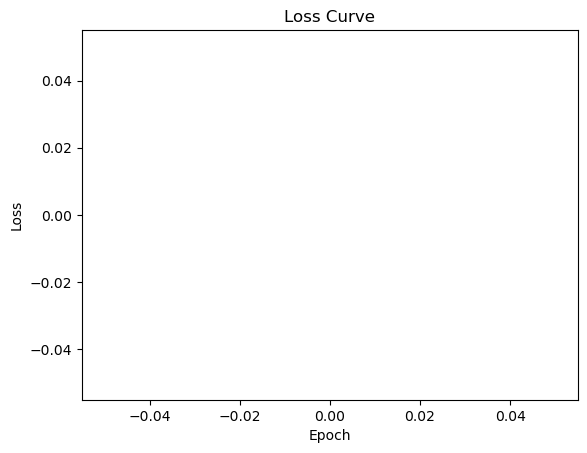

Epoch: 1, Loss: 34.18817922827238 + 0.0im
Epoch: 2, Loss: 29.591495313998294 + 0.0im
Epoch: 3, Loss: 25.533620171866612 + 0.0im
Epoch: 4, Loss: 22.118435308185095 + 0.0im
Epoch: 5, Loss: 19.39551030247795 + 0.0im
Epoch: 6, Loss: 16.56412909442539 + 0.0im
Epoch: 7, Loss: 14.473266549656385 + 0.0im
Epoch: 8, Loss: 12.7714498438277 + 0.0im
Epoch: 9, Loss: 10.882158192838073 + 0.0im
Epoch: 10, Loss: 9.637524111220811 + 0.0im
Epoch: 11, Loss: 8.339180224769327 + 0.0im
Epoch: 12, Loss: 7.2912823904018245 + 0.0im
Epoch: 13, Loss: 6.367589544529993 + 0.0im
Epoch: 14, Loss: 5.4298486678728315 + 0.0im
Epoch: 15, Loss: 4.616814648609619 + 0.0im
Epoch: 16, Loss: 3.922604903564652 + 0.0im
Epoch: 17, Loss: 3.3449393165218257 + 0.0im
Epoch: 18, Loss: 2.822467068729391 + 0.0im
Epoch: 19, Loss: 2.3985977480024956 + 0.0im
Epoch: 20, Loss: 2.0138675159511226 + 0.0im
Epoch: 21, Loss: 1.693073736647821 + 0.0im
Epoch: 22, Loss: 1.427133595707031 + 0.0im
Epoch: 23, Loss: 1.2166836653528683 + 0.0im
Epoch: 24,

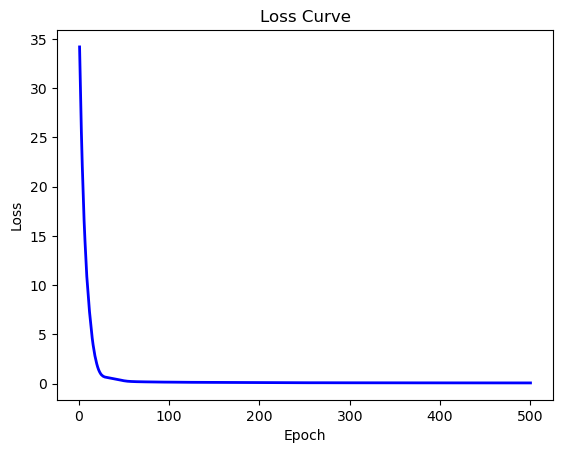

In [7]:
train(opt,layers,x,t,D,epochs=500)


In [8]:
@save "Attention_weight.jld2" W,

LoadError: ParseError:
[90m# Error @ [0;0m]8;;file://c:/Users/_s2220186/Desktop/Julia/LMP/research/In[8]#1:33\[90mIn[8]:1:33[0;0m]8;;\
@save "Attention_weight.jld2" W,[48;2;120;70;70m[0;0m
[90m#                               └ ── [0;0m[91mpremature end of input[0;0m